# Lab 5: TensorFlow with Keras
[\[Original instructions\]](https://lcc-cit.github.io/CS212-CourseMaterials/Labs/Lab05-ANN/GroupA/CS212_Lab05_Part2_Instructions_GroupA.html)

Written by Joshua Evans on 2026-11-09 with some assistance with Claude. AI generated code cells are labeled as such

## Objective:
My goal was to apply the same steps learned in the "Basic Image Classification" tutorial using a slightly more complex dataset: CIFAR-10

This program demonstrates my understanding of
- Loading a standard Keras dataset.
- Exploring and understanding the shape and type of your data.
- Adapting the model’s first layer to match your new data’s input shape.
- Building, compiling, training, and evaluating a basic neural network.

## CIFAR-10
The CIFAR-10 dataset is a “Hello, World” of computer vision. It contains 60,000 32x32 color images (50,000 training, 10,000 testing) divided into 10 classes:

- Airplane
- Automobile
- Bird
- Cat
- Deer
- Dog
- Frog
- Horse
- Ship
- Truck

## Steps


### Step 1: Import Libraries
Just like in the tutorial

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print(tf.__version__)

### Step 2: Load the Data
Specifically, the [CIFAR-10 dataset](https://cave.cs.toronto.edu/kriz/cifar.html). Again, same as in the tutorial

In [ ]:
# Load the CIFAR-10 dataset
cifar10 = tf.keras.datasets.cifar10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

# Define the class names for plotting
class_names = [
    'airplane',   # 0
    'automobile', # 1
    'bird',       # 2
    'cat',        # 3
    'deer',       # 4
    'dog',        # 5
    'frog',       # 6
    'horse',      # 7
    'ship',       # 8
    'truck'       # 9
]

### Step 3: Explore the Data
This data is different than the MNIST dataset in that:
- The images are *32x32* instead of 28x28
- The images have an additional color dimension in RGB space

In addition, the labels are an array of single item arrays, instead of just being an array of labels. There's no apparent purpose for this (other than legacy reasons) so I flatten the labels array for ease of use

In [ ]:
# Examine the dataset
print("Images shape:", train_images.shape)
print("Test images shape:", test_images.shape)
print("Test labels shape:", test_labels.shape)

# Explore the test labels, is there a point to the 2d array?
for i, label in enumerate(test_labels):
    if label.shape != (1,):
        print(f"Label at index {i} has unexpected shape: {label.shape}")
    if label[0] < 0 or label[0] >= len(class_names):
        print(f"Label at index {i} has unexpected value: {label[0]}")

# Preview one of the images
plt.figure()
plt.imshow(train_images[0]) # It's a frog!
plt.show()

In [ ]:
# Turns out there is no point to the 2d arrays, so flatten them
# Do it in a separate step to maintain document state
train_labels = train_labels.flatten()
test_labels = test_labels.flatten()
print("Test labels shape after flattening:", test_labels.shape)
print("Training labels shape after flattening:", train_labels.shape)

### Step 4: Preprocess the Data
Same as in the tutorial

In [ ]:
# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

### Step 5: Build the Model
This is the main "fill in the blank" of the lab. The trick is that the tutorial data is two dimensional since each pixel can be represented with a single grey-scale value - but the data for this lab is *three dimensional*, with the third dimension in "RGB" space.

Also, I noticed this warning in the logs when running the lab code:
```
UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
```
So I did as was suggested and added an `Input` layer where the shape is defined.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)), # It's 3D! OOoooOOoOOOOOoOooo
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

### Step 6: Compile the Model
Identical to the tutorial

In [ ]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### Step 7: Train the Model
Also identical to the tutorial. As indicated, the accuracy is considerably lower than the tutorial example

In [ ]:
model.fit(train_images, train_labels, epochs=10)

### Step 8: Evaluate Accuracy

Again, identical to the tutorial, but we are much less accurate

In [ ]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print('\nTest accuracy:', test_acc)

### Step 9: Make Predictions
Once again, identical to the tutorial. A bit more fun though! It's interesting to consider _why_ the model gets particular images wrong. Sometimes maybe a dog can look a bit like an automobile when you squint the right way ;)

In [ ]:
probability_model = tf.keras.Sequential([model, tf.keras.layers.Softmax()])
predictions = probability_model.predict(test_images)

def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    plt.imshow(img, cmap=plt.cm.binary)

    predicted_label = np.argmax(predictions_array)
    color = 'blue' if predicted_label == true_label else 'red'

    plt.xlabel(f"{class_names[predicted_label]} {100*np.max(predictions_array):2.0f}% ({class_names[true_label]})",
                                color=color)

def plot_value_array(i, predictions_array, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(10))
    plt.yticks([])
    thisplot = plt.bar(range(10), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)

    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')

def display_prediction(i):
    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plot_image(i, predictions[i], test_labels, test_images)
    plt.subplot(1,2,2)
    plot_value_array(i, predictions[i],  test_labels)
    plt.show()

display_prediction(0)
display_prediction(12)

# Plot the first X test images, their predicted labels, and the true labels.
# Color correct predictions in blue and incorrect predictions in red.
num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_image(i, predictions[i], test_labels, test_images)
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_value_array(i, predictions[i], test_labels)
plt.tight_layout()
plt.show()

## Bonus Challenge
What happens if we make another model with more layers? Does it improve performance?

One way to find out!

---

Instead of just making and running the "denser" model manually, I performed a series of tests and compared them directly with our statistics tools. I had Claude generate a test runner + renderer, and did a couple of runs to prove the result isn't a seeding fluke.

In summary, the data suggests an an additional "Dense" layer with a size of 64 improves accuracy by about 4%, just outside the margin of error, and with a p-value well below 0.05 it's very unlikely to be noise. In addition, the "denser" model produces much tighter result, with a margin of error half that of the original model.

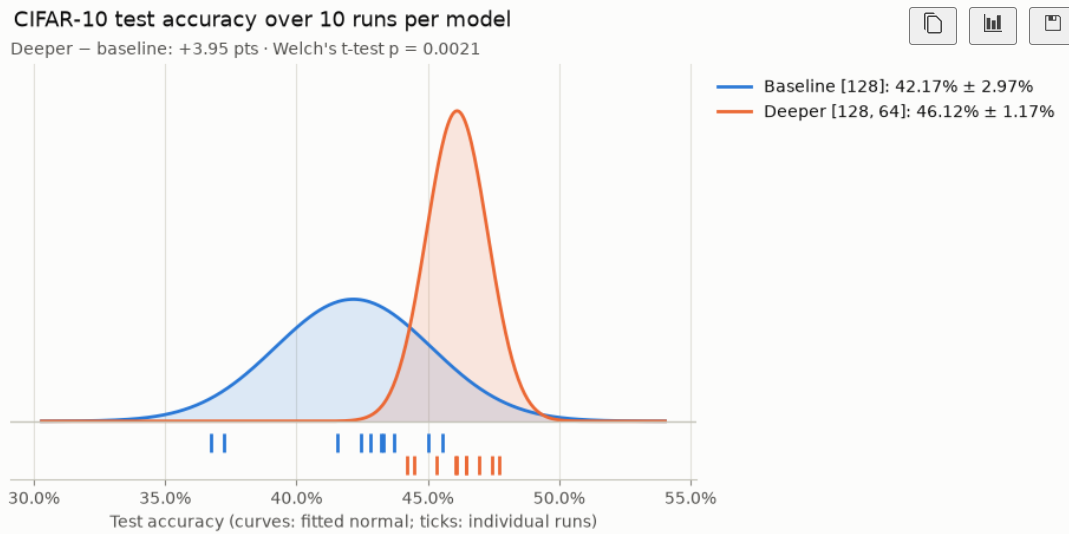
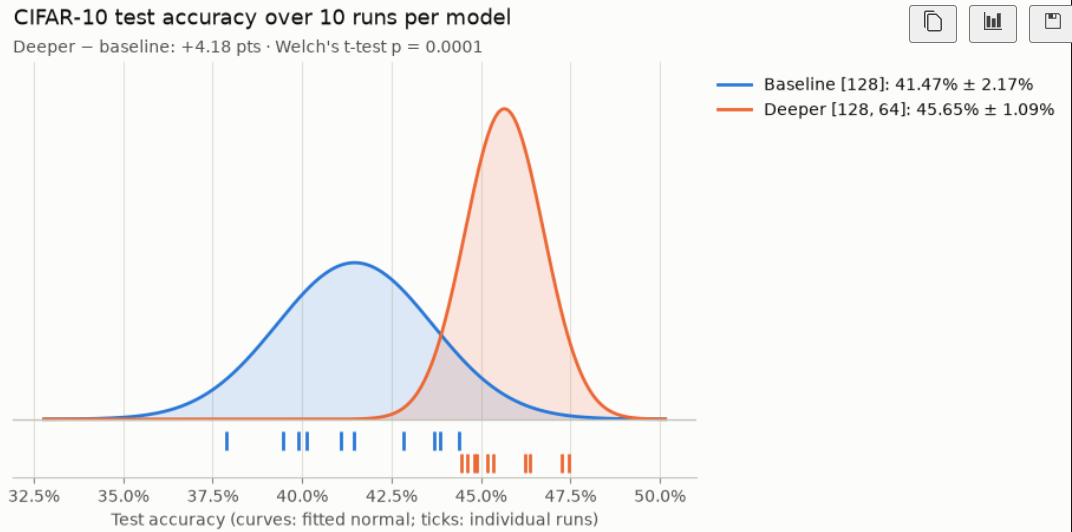

It's extremely interesting! Based on these data, I would say that adding a "deeper" model _does indeed_ improve accuracy, but to a limit. The main impact to the result is in the consistency. I hypothesize that adding another layer will improve performance further, but by something closer to 2%, and with an even tighter margin of error closer to 0.5%

So... let's find out!

---

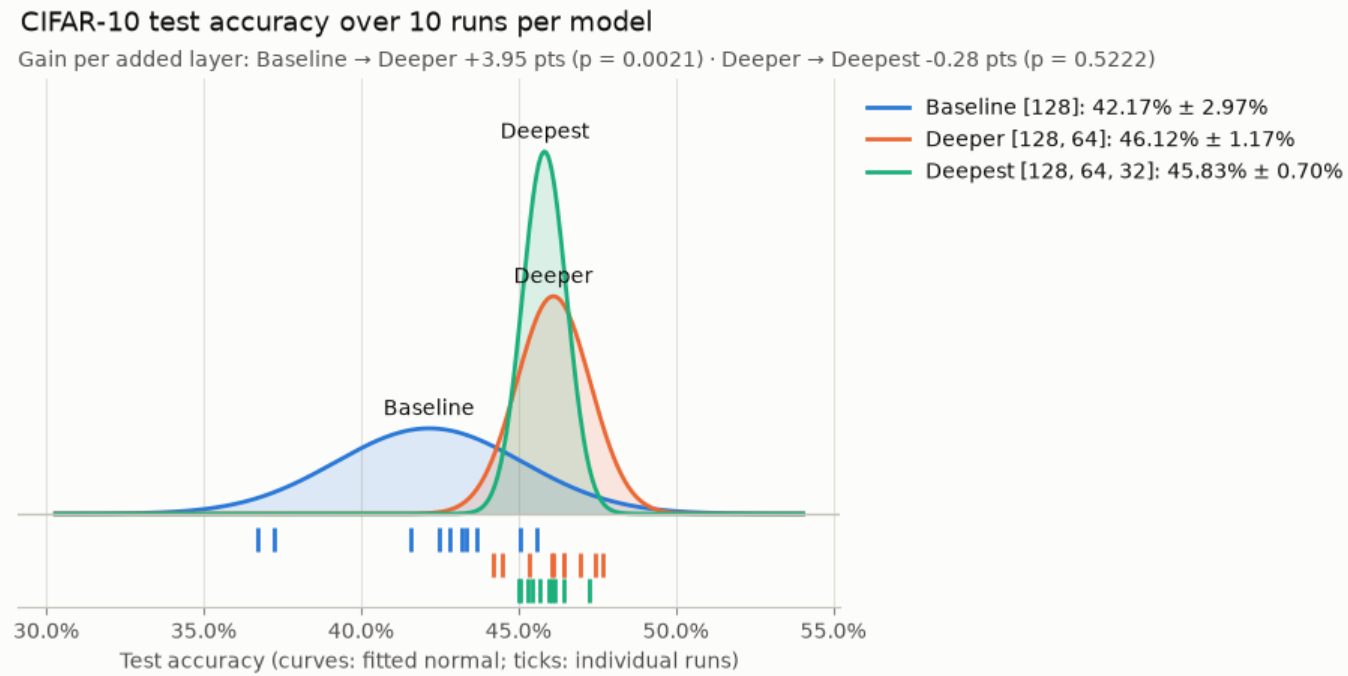

I ran a third test with an additional layer, and the results are fascinating! A third layer of size 32 does _not_ seem to improve accuracy at all, but it did reduce the result spread - just to a lesser degree than I expected

I could continue fiddling with the parameters, ~~but I think I can leave it here for this challenge~~ -so I did, see below. More layers doesn't necessarily improve accuracy, but it can improve performance in other ways up to a point. It's also possible that we would get much different results if, instead of bounding the number of epochs to 10 we only stopped training once performance no longer improves - we may be cutting training off early when running three layers... in fact...

---

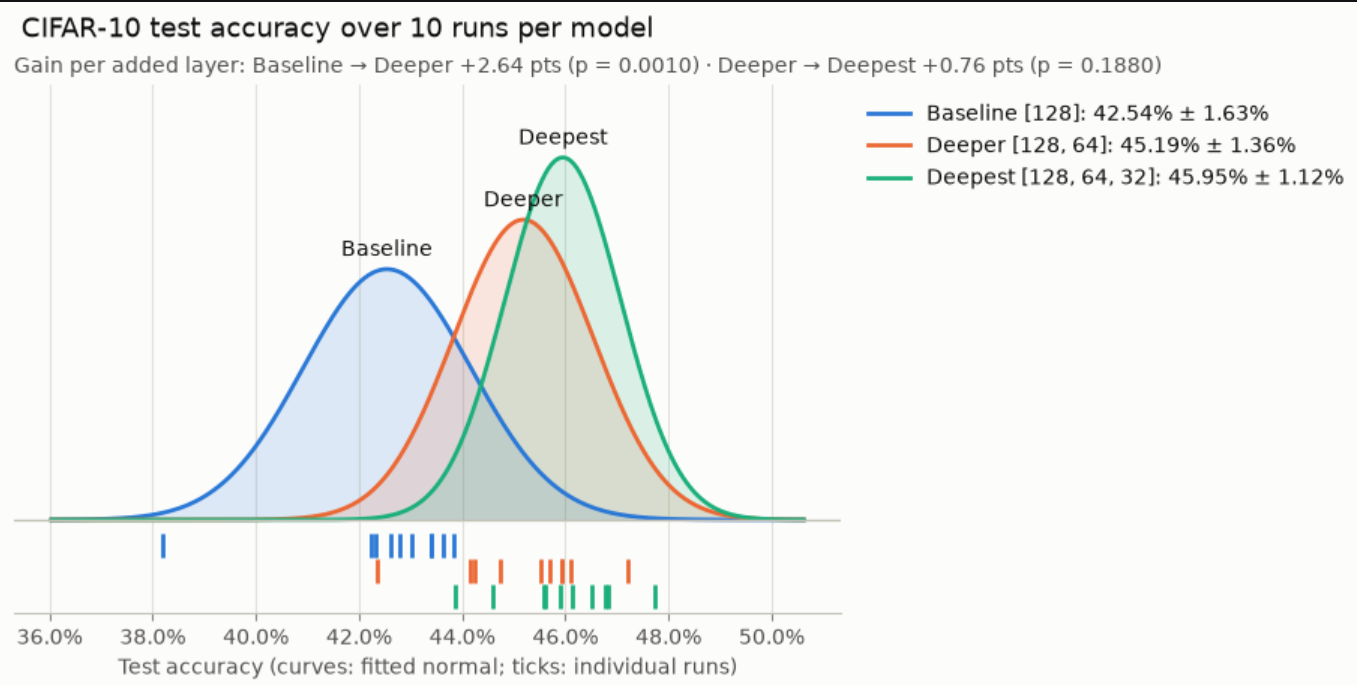

I refactored the runner so that the training only stopped once more epochs no longer improved performance. The results of this test are more in-line with my hypothesis. It turns out the 1 and 2 layer models happened to need about 10 epochs to reach peak performance. Allowing the 3 layer model run for longer continued to improve outcomes, but with _very strong_ diminishing returns. We were cutting the 3 layer model off too early in its training, but even accounting for that there are strong limits on what this core model can do on this dataset

In [ ]:
def build_model(hidden_sizes):
    """
    Return a freshly initialized, compiled model with one Dense layer per entry.
    
    Args:
        hidden_sizes (list of int): The number of units in each hidden Dense layer.

    Returns:
        tf.keras.Model: A compiled Keras model with the specified hidden layers.
    """
    layers = [tf.keras.Input(shape=(32, 32, 3)), tf.keras.layers.Flatten()]
    layers += [tf.keras.layers.Dense(n, activation="relu") for n in hidden_sizes]
    layers.append(tf.keras.layers.Dense(10))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer='adam',
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])
    return model



In [ ]:
# This cell was generated by Claude Opus 5.5 on 2026-11-09
import time
from itertools import pairwise

from matplotlib.ticker import PercentFormatter
from scipy import stats

# Models compared, in order of depth: name -> hidden Dense layer sizes
MODELS = {
    "Baseline": [128],
    "Deeper": [128, 64],
    "Deepest": [128, 64, 32],
}
MAX_EPOCHS = 50  # safety cap; early stopping normally ends training well before this
PATIENCE = 3  # epochs without validation-loss improvement before stopping
VALIDATION_SPLIT = 0.1  # share of the training set held back to decide when to stop
MIN_RUNS = 2

# Chart colours: categorical slots 1-3 and light-mode chrome from the dataviz reference palette
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
AXIS_LINE = "#c3c2b7"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CURVE_SPAN_SDS = 4  # x range covers each mean ± this many standard deviations
CURVE_POINTS = 400
# Spacing of the run-tick rows below the axis line, as a fraction of the tallest peak
TICK_ROW_GAP = 0.07
P_VALUE_FLOOR = 0.0001  # smaller p-values are shown as "p < 0.0001"


def run_trials(n_runs, seed_adjustment=0):
    """
    Train every model in MODELS n_runs times; return each model's test accuracies.

    Every run builds a fresh model with build_model and trains it on the
    training set minus a VALIDATION_SPLIT share held back for validation.
    Training stops once validation loss has not improved for PATIENCE epochs
    (or after MAX_EPOCHS), and the model is restored to its best epoch before
    it is scored on the test set. Run k of every model is seeded with
    k + seed_adjustment, so all models see the same shuffling. Shows Keras's
    training progress bars under a header naming the run and model, then a
    summary line per run with each model's test accuracy and best epoch.

    Args:
        n_runs (int): Runs per model, at least 2 (a spread needs two values).
        seed_adjustment (int): Offset added to every run's seed; change it to
            repeat the experiment with a different set of seeds.

    Returns:
        dict[str, np.ndarray]: Model name -> n_runs test accuracies in run
            order, with keys in MODELS order.

    Raises:
        ValueError: If n_runs is below 2 (checked before any training).
    """
    if n_runs < MIN_RUNS:
        raise ValueError(f"n_runs must be at least {MIN_RUNS}, got {n_runs}")

    results = {name: [] for name in MODELS}
    best_epochs = {}
    start = time.perf_counter()
    for run in range(n_runs):
        for name, hidden_sizes in MODELS.items():
            print(f"run {run + 1}/{n_runs} · {name} {hidden_sizes}")
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(run + seed_adjustment)
            model = build_model(hidden_sizes)
            early_stopping = tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True,
                verbose=1,
            )
            history = model.fit(
                train_images,
                train_labels,
                epochs=MAX_EPOCHS,
                validation_split=VALIDATION_SPLIT,
                callbacks=[early_stopping],
                verbose=1,
            )
            best_epochs[name] = int(np.argmin(history.history["val_loss"])) + 1
            scores = model.evaluate(
                test_images, test_labels, verbose=0, return_dict=True
            )
            results[name].append(scores["accuracy"])
        summary = ", ".join(
            f"{name} {accs[-1]:.2%} (best epoch {best_epochs[name]})"
            for name, accs in results.items()
        )
        elapsed = time.perf_counter() - start
        print(
            f"=> run {run + 1}/{n_runs} test accuracy: {summary}  ({elapsed:.0f}s elapsed)"
        )
    return {name: np.array(accs) for name, accs in results.items()}


def plot_comparison(results):
    """
    Draw every model's test-accuracy distribution in one panel.

    Each model gets a normal curve fitted to its runs (sample mean and standard
    deviation), labelled with its name at the peak, and a tick per actual run
    along the bottom. The legend gives each model's mean ± SD. The subtitle gives
    the gain from each added layer (each model against the one before it in
    MODELS order) with Welch's t-test p-value.

    Args:
        results (dict[str, array-like]): Model name -> test accuracies, as
            returned by run_trials.

    Returns:
        matplotlib.figure.Figure: The figure (call plt.show() to display it).
    """
    samples = {name: np.asarray(accs, dtype=float) for name, accs in results.items()}
    fits = {name: (accs.mean(), accs.std(ddof=1)) for name, accs in samples.items()}
    x = np.linspace(
        min(mean - CURVE_SPAN_SDS * sd for mean, sd in fits.values()),
        max(mean + CURVE_SPAN_SDS * sd for mean, sd in fits.values()),
        CURVE_POINTS,
    )
    curves = {name: stats.norm.pdf(x, mean, sd) for name, (mean, sd) in fits.items()}
    tallest = max(curve.max() for curve in curves.values())

    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained", facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    for row, (name, color) in enumerate(zip(samples, SERIES_COLORS, strict=False)):
        accs, (mean, sd), curve = samples[name], fits[name], curves[name]
        ax.fill_between(x, curve, color=color, alpha=0.15, linewidth=0)
        ax.plot(
            x,
            curve,
            color=color,
            linewidth=2,
            label=f"{name} {MODELS[name]}: {mean:.2%} ± {sd:.2%}",
        )
        ax.annotate(
            name,
            xy=(mean, curve.max()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=INK,
            fontsize=10,
        )
        tick_y = -(row + 1) * TICK_ROW_GAP * tallest
        ax.plot(
            accs,
            np.full(accs.size, tick_y),
            linestyle="none",
            marker="|",
            markersize=12,
            markeredgewidth=2,
            color=color,
        )

    ax.axhline(0, color=AXIS_LINE, linewidth=1)
    ax.set_ylim(-(len(samples) + 0.7) * TICK_ROW_GAP * tallest, tallest * 1.2)
    ax.set_yticks([])
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS_LINE)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.tick_params(axis="x", colors=INK_MUTED, labelcolor=INK_SECONDARY)
    ax.grid(axis="x", color=GRIDLINE, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(
        "Test accuracy (curves: fitted normal; ticks: individual runs)",
        color=INK_SECONDARY,
    )

    steps = []
    for previous, current in pairwise(samples):
        p_value = stats.ttest_ind(
            samples[current], samples[previous], equal_var=False
        ).pvalue
        p_text = (
            f"p < {P_VALUE_FLOOR}" if p_value < P_VALUE_FLOOR else f"p = {p_value:.4f}"
        )
        gain = (samples[current].mean() - samples[previous].mean()) * 100
        steps.append(f"{previous} → {current} {gain:+.2f} pts ({p_text})")
    n_runs = len(next(iter(samples.values())))
    fig.suptitle(
        f"CIFAR-10 test accuracy over {n_runs} runs per model",
        x=0.01,
        ha="left",
        color=INK,
        fontsize=13,
    )
    ax.set_title(
        "Gain per added layer: " + " · ".join(steps),
        loc="left",
        color=INK_SECONDARY,
        fontsize=10,
    )
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, labelcolor=INK)
    return fig

### Bonus Challenge Call-site
The bonus challenge code is run in the following two cells, first the trials are actually performed, then a plot is generated from the data. The trials can take a good deal of time, especially when performing many runs. Logs are passed through, so they can be observed in this document.

In [ ]:
# Try 2 runs first to see how long one run takes with early stopping; then go to 10
N_RUNS = 10
results = run_trials(N_RUNS)

In [ ]:
plot_comparison(results)
plt.show()